# ML Recursive models 

## Setup

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

from src.config import GB_PARAMS, HORIZONS, N_TEST, RF_PARAMS
from src.evaluation import error_metrics, seasonal_naive
from src.visualization import plot_forecasts, plot_importances
from src.ML_models import make_supervised, recursive_forecast, tune_gb_trees

LAGS = [1, 2, 7, 14]
DATA_DIR = Path("data")
FIG_DIR = Path("figures/ml_recursive")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
data = pd.read_csv(DATA_DIR / "model_data.csv", index_col="date", parse_dates=True)
y, X = data["x"], data.drop(columns="x")
X_tr, y_tr, X_te, y_te = make_supervised(X, y, LAGS, N_TEST)
print(f"Train: {X_tr.shape}, test: {X_te.shape}")


Train: (2177, 28), test: (365, 28)


## RF without lags

RF without lags: RMSE = 33.401, MAE = 28.233


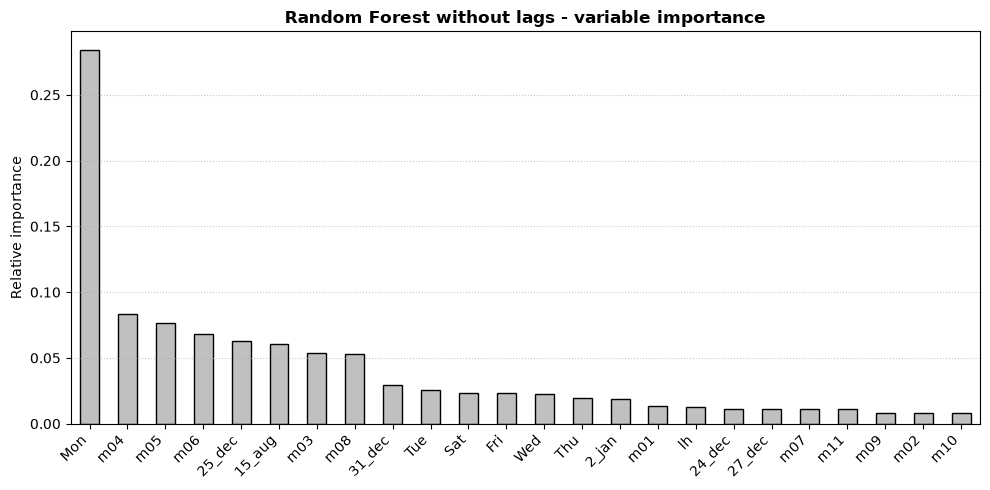

In [3]:
rf_base = RandomForestRegressor(**RF_PARAMS).fit(X.iloc[:-N_TEST], y.iloc[:-N_TEST])
base_fc = pd.Series(rf_base.predict(X.iloc[-N_TEST:]), index=y_te.index)
m = error_metrics(y_te, base_fc)
print(f"RF without lags: RMSE = {m['RMSE']:.3f}, MAE = {m['MAE']:.3f}")
plot_importances(rf_base, "Random Forest without lags - variable importance", color="silver",
                 save_name=FIG_DIR / "rf_no_lags_importance.png")

## Random Forest

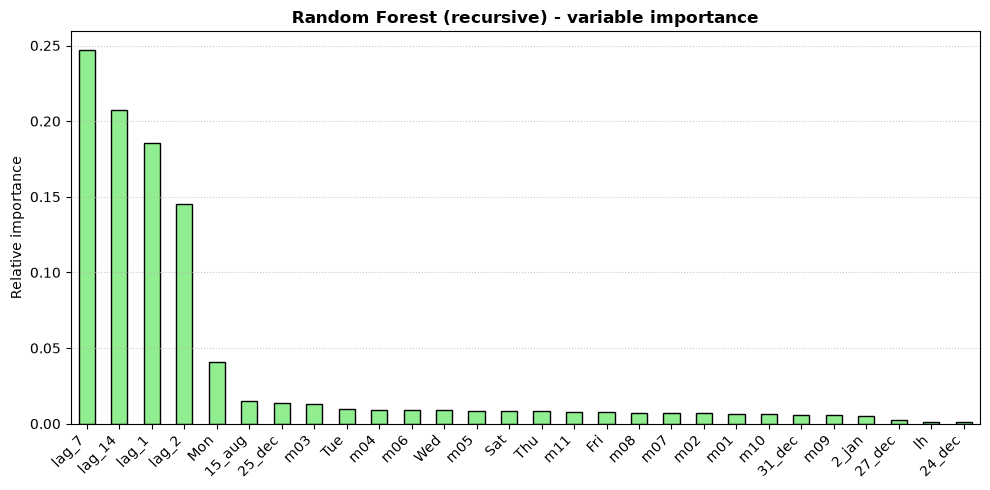

In [4]:
rf = RandomForestRegressor(**RF_PARAMS).fit(X_tr, y_tr)
plot_importances(rf, "Random Forest (recursive) - variable importance", save_name=FIG_DIR / "rf_importance.png")

## Gradient boosting

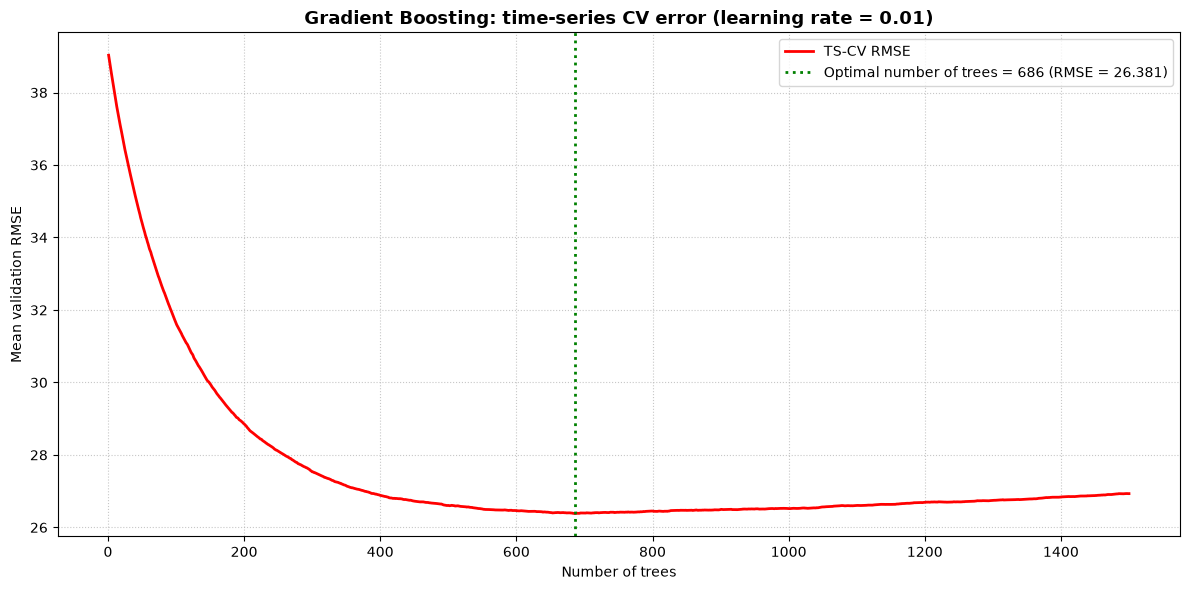

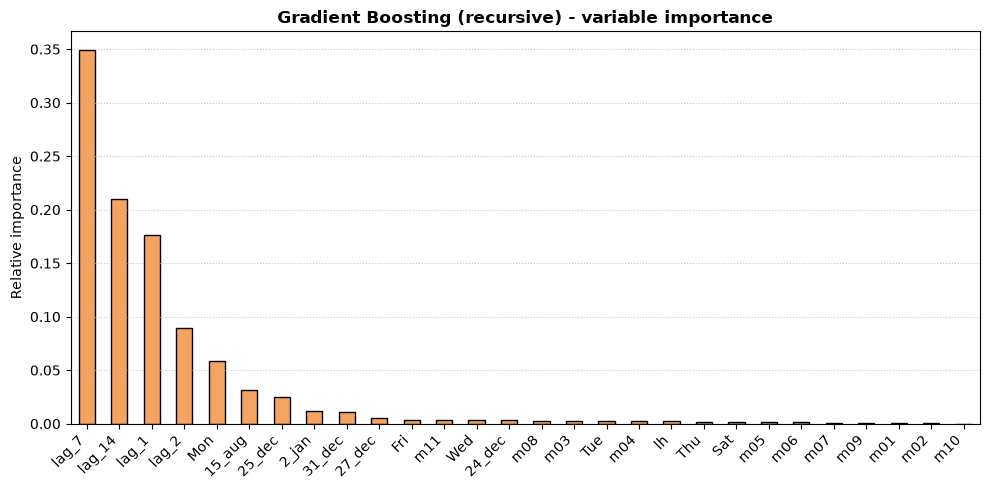

In [5]:
n_trees, cv_rmse = tune_gb_trees(X_tr, y_tr, max_trees=1500, **GB_PARAMS)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(range(1, len(cv_rmse) + 1), cv_rmse, color="red", linewidth=2, label="TS-CV RMSE")
ax.axvline(n_trees, color="green", linestyle=":", linewidth=2,
        label=f"Optimal number of trees = {n_trees} (RMSE = {cv_rmse[n_trees - 1]:.3f})")
ax.set_title(f"Gradient Boosting: time-series CV error (learning rate = {GB_PARAMS['learning_rate']})",
            fontsize=13, fontweight="bold")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Mean validation RMSE")
ax.grid(True, linestyle=":", alpha=0.7)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "gbm_tscv.png", dpi=300, bbox_inches="tight")
plt.show()

gb = GradientBoostingRegressor(n_estimators=n_trees, **GB_PARAMS).fit(X_tr, y_tr)
plot_importances(gb, "Gradient Boosting (recursive) - variable importance", color="sandybrown",
                save_name=FIG_DIR / "gbm_importance.png")


## Recursive forecast

In [6]:
forecasts, rows = {}, []
for h in HORIZONS:
    for name, model in [("RF", rf), ("GBM", gb)]:
        forecasts[f"{name}_h{h}"] = recursive_forecast(model, X_tr, X_te, h)
        rows.append({"h": h, "model": name, **error_metrics(y_te, forecasts[f"{name}_h{h}"])})

results = pd.DataFrame(rows)
display(results.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))

# %% Save the forecasts for the comparison notebook
pd.DataFrame(forecasts).to_csv(DATA_DIR / "ml_recursive_forecasts.csv", index_label="date")

RMSE             MAE        
model     GBM      RF     GBM      RF
h                                    
1      22.682  23.434  18.163  18.654
3      23.185  24.036  18.512  18.968
7      23.268  24.564  18.540  19.503
14     24.654  26.554  19.877  21.076
30     26.494  27.394  20.912  21.801

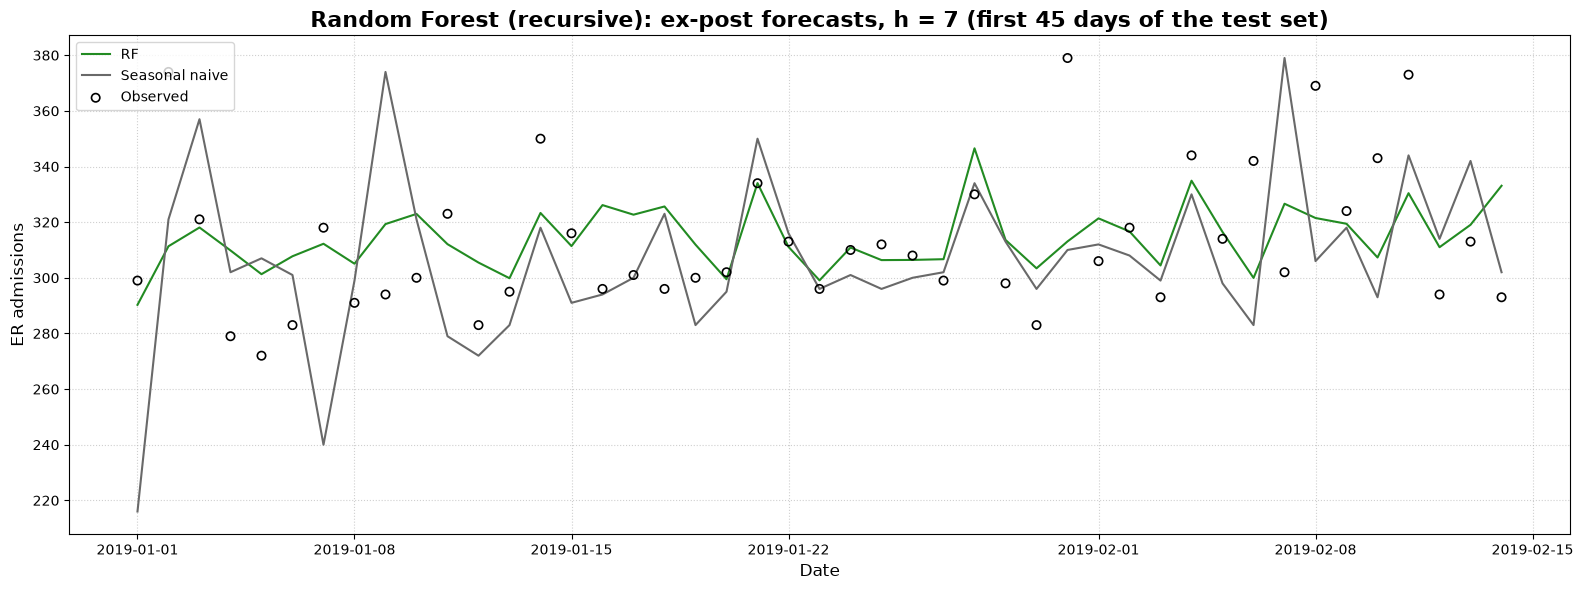

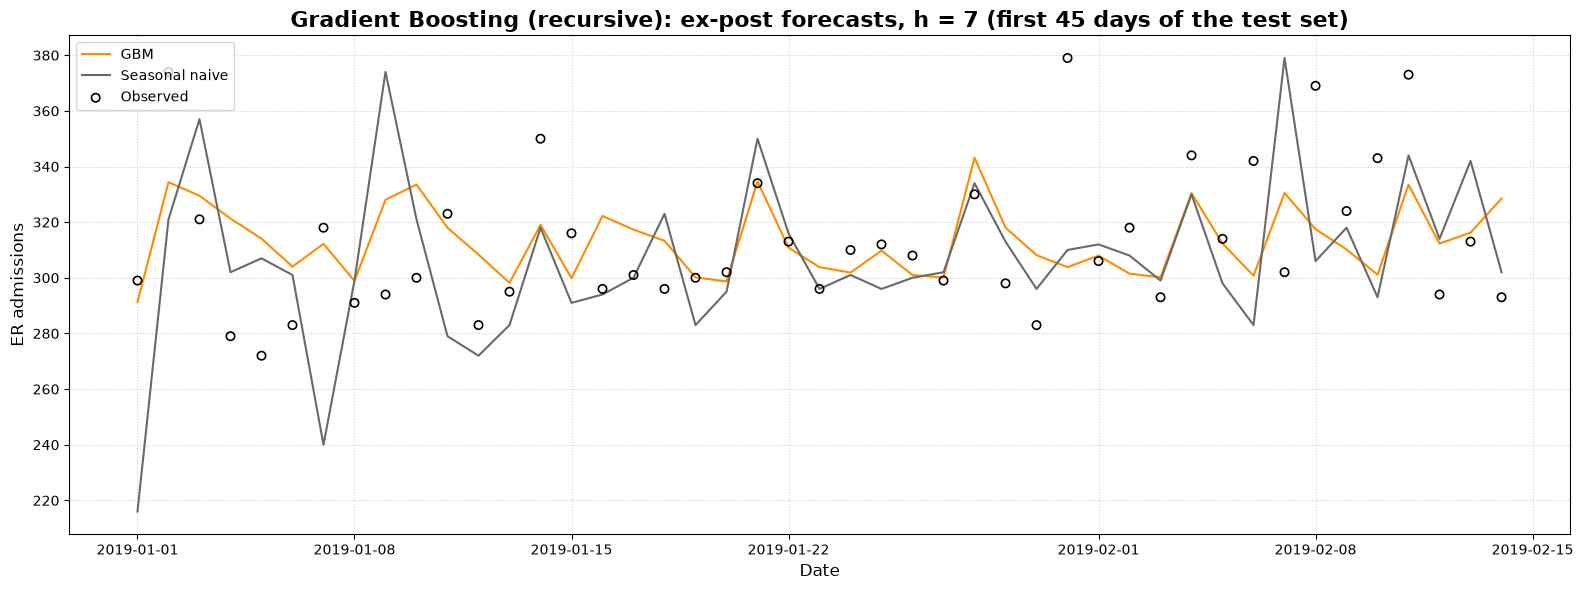

In [7]:
h, days = 7, 45
naive = seasonal_naive(y, N_TEST, h).iloc[:days]
for name, title in [("RF", "Random Forest"), ("GBM", "Gradient Boosting")]:
    plot_forecasts(
        y_te.iloc[:days],
        pd.DataFrame({name: forecasts[f"{name}_h{h}"].iloc[:days], "Seasonal naive": naive}),
        title=f"{title} (recursive): ex-post forecasts, h = {h} (first {days} days of the test set)",
        save_name=FIG_DIR / f"{name.lower()}_forecasts_h{h}.png",
    )

## Robustness check: Recursive ML on first differences

In [8]:
import numpy as np

def recursive_forecast_diff(model, X_train, X_test, y, h):
    X_all = pd.concat([X_train, X_test])
    columns = X_all.columns
    lag_cols = {j: int(c.split("_" )[1]) for j, c in enumerate(columns) if c.startswith("lag_")}

    first = len(X_train) - h + 1
    rows = first + np.arange(len(X_test))[:, None] + np.arange(h)
    paths = X_all.to_numpy(dtype=float)[rows]

    step_preds = []
    for s in range(h):
        pred = model.predict(pd.DataFrame(paths[:, s], columns=columns))
        step_preds.append(pred)
        for j, k in lag_cols.items():
            if s + k < h:
                paths[:, s + k, j] = pred
    
    cum_diff = np.sum(step_preds, axis=0)
    y_orig = y.shift(h).iloc[-len(X_test):].to_numpy()
    pred_level = y_orig + cum_diff
    return pd.Series(pred_level, index=X_test.index)

dy = y.diff()
X_tr_diff, dy_tr, X_te_diff, dy_te = make_supervised(X, dy, LAGS, N_TEST)
X_tr_diff, dy_tr = X_tr_diff.iloc[1:], dy_tr.iloc[1:]

rf_diff = RandomForestRegressor(**RF_PARAMS).fit(X_tr_diff, dy_tr)
n_trees, _ = tune_gb_trees(X_tr_diff, dy_tr, max_trees=1500, **GB_PARAMS)
gb_diff = GradientBoostingRegressor(n_estimators=n_trees, **GB_PARAMS).fit(X_tr_diff, dy_tr)

diff_forecasts, diff_rows = {}, []
for h in HORIZONS:
    for name, model in [("RF_diff", rf_diff), ("GBM_diff", gb_diff)]:
        diff_forecasts[f"{name}_h{h}"] = recursive_forecast_diff(model, X_tr_diff, X_te_diff, y, h)
        diff_rows.append({"h": h, "model": name, **error_metrics(y_te, diff_forecasts[f"{name}_h{h}"])})
    print(f"Completed recursive diff h = {h}")

diff_results = pd.DataFrame(diff_rows)
display(diff_results.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))


Completed recursive diff h = 1


Completed recursive diff h = 3


Completed recursive diff h = 7


Completed recursive diff h = 14


Completed recursive diff h = 30


RMSE              MAE        
model GBM_diff RF_diff GBM_diff RF_diff
h                                      
1       23.802  24.561   18.980  19.612
3       26.323  27.041   20.774  21.485
7       25.236  27.288   19.552  21.321
14      29.888  33.557   23.701  26.048
30      34.940  41.828   27.440  32.213

## Comparison: Levels vs Differences

In [9]:
comp_df = pd.concat([results, diff_results])
display(comp_df.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))

pd.DataFrame(diff_forecasts).to_csv(DATA_DIR / "ml_recursive_diff_forecasts.csv", index_label="date")


RMSE                              MAE                         
model     GBM GBM_diff      RF RF_diff     GBM GBM_diff      RF RF_diff
h                                                                      
1      22.682   23.802  23.434  24.561  18.163   18.980  18.654  19.612
3      23.185   26.323  24.036  27.041  18.512   20.774  18.968  21.485
7      23.268   25.236  24.564  27.288  18.540   19.552  19.503  21.321
14     24.654   29.888  26.554  33.557  19.877   23.701  21.076  26.048
30     26.494   34.940  27.394  41.828  20.912   27.440  21.801  32.213